<a href="https://colab.research.google.com/github/valdirsillva/deep-learning-challenge/blob/master/Deep_Learning_A_Z_challenge_one_image_classification_(task_1)_MNIST_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Tarefa: Classificar somente uma imagem

O objetivo é você fazer a leitura de uma imagem da base de dados **MNIST** abordada na seção anterior e classificar o dígito correspondente. Siga as seguintes instruções:

- Você não precisará utilizar a função image  do Keras, pois as imagens dessa base de dados já estão no formato correto (não é necessário ler elas do disco).

- Efetue o teste utilizando qualquer imagem da base de dados de teste

- O **MNIST** apresenta 10 classes, portanto, utilizamos a função de ativação softmax  e o resultado será uma matriz com as probabilidades para cada uma das classes

Ao final, você deve mostrar uma mensagem indicando a qual classe a imagem pertence

In [1]:
!pip uninstall tensforflow

In [ ]:
!pip install tensorflow==2.16.1

In [18]:
import tensorflow as tf
import keras
import numpy as np

tf.__version__, keras.__version__, np.__version__

# Versões esperadas para essa implementação: ('2.16.1', '3.8.0', '1.26.4')

('2.16.1', '3.8.0', '1.26.4')

In [2]:
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import InputLayer, Dense, Flatten, Dropout, Conv2D, MaxPooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import utils as np_utils

In [3]:
# Passo 01: Carregar base de dados
(X_treinamento, y_treinamento), (X_teste, y_teste) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [4]:
X_treinamento.shape, y_treinamento.shape

((60000, 28, 28), (60000,))

In [5]:
# Passo 02: Ajuste das dimensões

X_treinamento = X_treinamento.reshape(X_treinamento.shape[0], 28, 28, 1)
X_teste = X_teste.reshape(X_teste.shape[0], 28, 28, 1)
X_treinamento = X_treinamento.astype("float32")
X_teste = X_teste.astype("float32")
X_treinamento /= 255.0
X_teste /= 255.0

y_treinamento = np_utils.to_categorical(y_treinamento, 10)
y_teste = np_utils.to_categorical(y_teste, 10)

In [6]:
X_treinamento.shape, y_treinamento.shape

((60000, 28, 28, 1), (60000, 10))

In [7]:
# Passo 03: Criar a arquitetuda da rede neural
classificador = Sequential()

classificador.add(InputLayer( shape = (28, 28, 1)))
classificador.add(Conv2D(32, (3, 3), activation='relu'))
classificador.add(MaxPooling2D(pool_size=(2, 2)))
classificador.add(Flatten())

classificador.add(Dense(units = 128, activation='relu'))
classificador.add(Dense(units = 10, activation='softmax'))
classificador.compile(loss ='categorical_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [8]:
gerador_treinamento = ImageDataGenerator(rotation_range =7,
                                         horizontal_flip=True,
                                         shear_range = 0.2,
                                         height_shift_range = 0.07,
                                         zoom_range = 0.2 )

In [9]:
gerador_teste = ImageDataGenerator()

In [12]:
# Criação base de treinamento
# # O método flow() do tf.keras.preprocessing.image.ImageDataGenerator é usado para gerar lotes (batches) de dados de imagem e rótulos diretamente a partir de arrays NumPy já carregados na memória
base_treinamento = gerador_treinamento.flow(X_treinamento, y_treinamento, batch_size = 128)

In [13]:
base_teste = gerador_teste.flow(X_teste, y_teste, batch_size = 128)

In [14]:
# Treinamento da rede neural
classificador.fit(base_treinamento, epochs = 10, validation_data=base_teste )

Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


469/469 ━━━━━━━━━━━━━━━━━━━━ 42s 88ms/step - accuracy: 0.7498 - loss: 0.7824 - val_accuracy: 0.9315 - val_loss: 0.2110
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 41s 87ms/step - accuracy: 0.9189 - loss: 0.2565 - val_accuracy: 0.9544 - val_loss: 0.1325
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 42s 90ms/step - accuracy: 0.9440 - loss: 0.1831 - val_accuracy: 0.9693 - val_loss: 0.0966
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 41s 86ms/step - accuracy: 0.9534 - loss: 0.1515 - val_accuracy: 0.9693 - val_loss: 0.0948
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 40s 86ms/step - accuracy: 0.9591 - loss: 0.1308 - val_accuracy: 0.9750 - val_loss: 0.0778
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 40s 85ms/step - accuracy: 0.9632 - loss: 0.1164 - val_accuracy: 0.9733 - val_loss: 0.0835
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 40s 86ms/step - accuracy: 0.9665 - loss: 0.1064 - val_accuracy: 0.9755 - val_loss: 0.0759
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 41s 86ms/step - accuracy: 0.9687 - loss: 0.0982 - val_accurac

In [46]:
# Obter o resultado da Predição

# Exemplo pegando o primeiro elemento de uma base de teste X_teste
imagem_teste = X_teste[7]
# Importante verificar se a 'imagem' está no formato esperado pela rede
imagem_teste.shape

(28, 28, 1)

In [47]:
# O Keras espera um lote (batch), então adicionamos uma dimensão extra na frente: de (28, 28, 1) para (1, 28, 28, 1)
imagem_com_batch = np.expand_dims(imagem_teste, axis = 0)

In [48]:
# Obter a matriz/vetor de probabilidades usando a função predict
previsoes = classificador.predict(imagem_com_batch)
print("probabilidades para cada classe (0 a 9):", previsoes)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
probabilidades para cada classe (0 a 9): [[6.5032509e-08 2.2765379e-08 1.0099554e-04 5.9767294e-06 1.6346242e-02
  2.8735932e-04 3.9067953e-09 1.7024437e-04 6.5839401e-04 9.8243064e-01]]


In [49]:
# Encontrar a classe com a maior probabilidade (o dígito previsto)
classe_prevista = np.argmax(previsoes)

In [50]:
# 4. Mostrar a mensagem final indicando a classe a que a imagem pertence
print(f"A imagem pertence à classe: {classe_prevista}")

A imagem pertence à classe: 9


In [26]:
import matplotlib.pyplot as plt


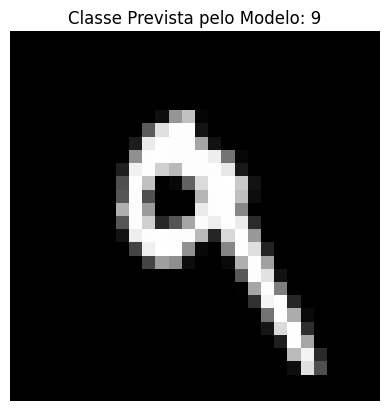

In [51]:
# Plotar a imagem

imagem_para_exibir = np.squeeze(imagem_teste)

# Exibir a imagem usando o mapa de cores 'gray' (escala de cinza)
plt.imshow(imagem_para_exibir, cmap='gray')
plt.title(f"Classe Prevista pelo Modelo: {classe_prevista}")
plt.axis('off')  # Oculta os eixos X e Y para ficar mais limpo
plt.show()